# Tutorial 2: S1 photon propagation

In tutorial 1 we turned energy deposits into numbers of photons, electrons and excitons (`microphysics_summary`). Now we follow the **photons**. They are emitted at the interaction point within a few ns to µs, travel through the liquid xenon, and a fraction of them is detected by the PMTs. The light seen right after the interaction is the **S1** signal.

ember simulates the S1 with two plugins, ported from fuse:

```
microphysics_summary
  └─ S1PhotonHits         → s1_photon_hits          (how many photons are detected?)
  └─ S1PhotonPropagation  → propagated_s1_photons   (which PMT, at what time, with which gain?)
```

`s1_photon_hits` has one row per interaction. `propagated_s1_photons` has **one row per detected photon**. Later, the PMT and DAQ simulation turns these photons into waveforms.

The S1 branch needs three inputs that are not numbers but maps or tables. ember ships simple dummy versions in `ember/dummy_maps`; the notebooks in `map_generators/` explain how they are made.

| Input | What it describes | Used by |
|---|---|---|
| S1 light collection efficiency (LCE) map | for each position and each PMT: PE per emitted photon | both plugins |
| S1 optical propagation timing map | how long a photon travels from the interaction to the top or bottom array | `S1PhotonPropagation` |
| SPE area distributions | how much charge one photoelectron produces in each PMT | `S1PhotonPropagation` |

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import strax

import ember

## 1. Simulate the microphysics

We reuse the 40 keV betas from tutorial 1. If you have not run tutorial 1, run its section 2 first to create `beta_40keV.csv`.

In [2]:
st = ember.ember_context(output_folder="./strax_data")
st.set_config({"input_file": "beta_40keV.csv"})

run_id = "000001"
microphysics_summary = st.get_array(run_id, "microphysics_summary")
print("Interactions:", len(microphysics_summary))
print("Mean number of photons:", microphysics_summary["photons"].mean())

Loading microphysics_summary: |          | 0.00 % [00:00<?]

Interactions: 1000
Mean number of photons: 2139.482


## 2. The S1 light collection efficiency map

Only a fraction of the emitted photons produces a signal: photons are absorbed on the PTFE walls, on the electrodes or in the xenon, are reflected at the liquid surface, or miss the PMTs. The **LCE map** stores for every position $(x, y, z)$ and every PMT channel $c$

$$\mathrm{LCE}_c(x, y, z) = \text{mean number of PE in PMT } c \text{ per photon emitted at } (x, y, z).$$

It is a 4D array with shape `(n_x, n_y, n_z, n_PMTs)`. It contains two pieces of information:

* the **sum over all PMTs**, $\varepsilon_\mathrm{LCE}(x, y, z) = \sum_c \mathrm{LCE}_c$, is the local light detection efficiency (on average $g_1$),
* the **relative values** $\mathrm{LCE}_c / \varepsilon_\mathrm{LCE}$ form the hit pattern: which PMT sees the light.

In a real experiment this map comes from an optical Geant4 simulation. ember's dummy map has the same value for every PMT of one array, a top/bottom split that changes with depth, and a light yield that is higher at the bottom and lower near the wall.

The map is loaded with the `ember_map://` protocol, the same way the plugins load it:

In [3]:
s1_lce_map = strax.URLConfig.evaluate_dry("ember_map://s1_pattern_map_dummy.pkl?method=linear")

n_top_pmts = strax.URLConfig.evaluate_dry("detector://n_top_pmts")
n_tpc_pmts = strax.URLConfig.evaluate_dry("detector://n_tpc_pmts")
g1 = strax.URLConfig.evaluate_dry("detector://g1")
z_cathode = strax.URLConfig.evaluate_dry("detector://z_cathode")
tpc_radius = strax.URLConfig.evaluate_dry("detector://tpc_radius")

print("Grid axes:", s1_lce_map.axis_names)
print("Number of channels in the map:", s1_lce_map.values.shape[-1], "(detector:", n_tpc_pmts, ")")

Grid axes: ['x', 'y', 'z']
Number of channels in the map: 494 (detector: 494 )


Evaluate the map along the TPC axis ($x = y = 0$) and split the light into the top and bottom array. The total is the light detection efficiency, the ratio top/total is the **area fraction top (AFT)**:

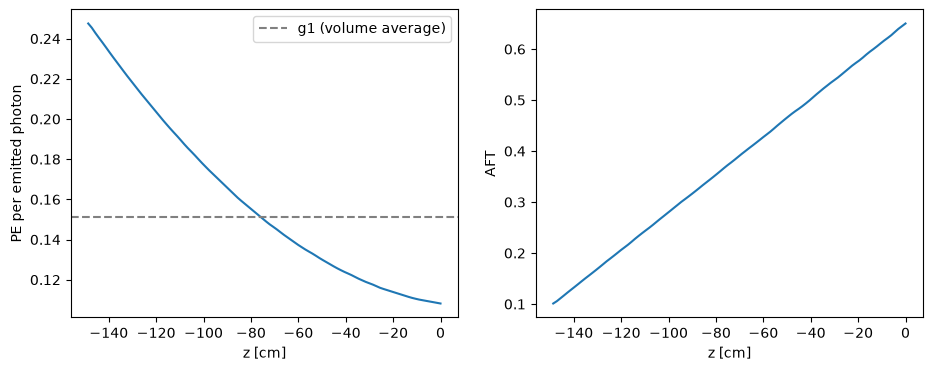

In [4]:
z_values = np.linspace(z_cathode, 0, 100)
positions_on_axis = np.column_stack([np.zeros(100), np.zeros(100), z_values])

lce_per_channel = s1_lce_map(positions_on_axis)
lce_top = lce_per_channel[:, :n_top_pmts].sum(axis=1)
lce_total = lce_per_channel.sum(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(z_values, lce_total)
axes[0].axhline(g1, color="gray", linestyle="--", label="g1 (volume average)")
axes[0].set_xlabel("z [cm]")
axes[0].set_ylabel("PE per emitted photon")
axes[0].legend()
axes[1].plot(z_values, lce_top / lce_total)
axes[1].set_xlabel("z [cm]")
axes[1].set_ylabel("AFT")
plt.show()

## 3. `S1PhotonHits`: how many photons are detected?

For an interaction with $N_\gamma$ photons at $(x, y, z)$, the number of detected photons is drawn from a binomial distribution:

$$N_\mathrm{hits} \sim \mathrm{Binomial}\left(N_\gamma,\; p\right), \qquad p = \frac{\varepsilon_\mathrm{LCE}(x, y, z) \cdot \varepsilon_{S1}}{1 + p_\mathrm{DPE}}.$$

Why divide by $1 + p_\mathrm{DPE}$? The map is in PE, but a VUV photon can release **two** photoelectrons from the photocathode (double photoelectron emission, DPE) with probability $p_\mathrm{DPE} \approx 0.22$. The plugin counts *photons*; the second PE is added later in `S1PhotonPropagation`. On average both effects cancel and the S1 has $\varepsilon_\mathrm{LCE} \cdot N_\gamma$ PE.

PMTs that are switched off (gain 0) are removed from the sum $\varepsilon_\mathrm{LCE}$, so they also reduce the total light.

### Settings

| Option | Default | Meaning |
|---|---|---|
| `s1_pattern_map` | `ember_map://s1_pattern_map_dummy.pkl?method=linear` | LCE map (PE per emitted photon, per channel) |
| `s1_detection_efficiency` | `detector://s1_detection_efficiency` (1.0) | extra global factor $\varepsilon_{S1}$, e.g. to tune the S1 size |
| `p_double_pe_emission` | `detector://p_double_pe_emission` (0.219) | DPE probability $p_\mathrm{DPE}$ (fuse spells it `p_double_pe_emision`) |
| `gain_model_mc` | `ember_pmt_to_pe://` | conversion factor ADC → PE per channel; channels with 0 are switched off |
| `digitizer_bits`, `digitizer_voltage_range`, `pmt_circuit_load_resistor` | `detector://…` | turn `gain_model_mc` into PMT gains |

You can list all options of a data type and their current values with `st.show_config`:

In [5]:
st.show_config("s1_photon_hits")

,option,default,current,applies_to,help
0,debug,False,<OMITTED>,"(s1_photon_hits,)",Show debug informations
1,deterministic_seed,True,<OMITTED>,"(s1_photon_hits,)","Set the random seed from lineage and run_id, o..."
2,user_defined_random_seed,None,<OMITTED>,"(s1_photon_hits,)",Define the random seed manually. You need to s...
3,gain_model_mc,ember_pmt_to_pe://,<OMITTED>,"(s1_photon_hits,)",ADC-to-PE factor per channel; channels with 0 ...
4,s1_pattern_map,ember_map://s1_pattern_map_dummy.pkl?method=li...,<OMITTED>,"(s1_photon_hits,)",S1 light collection efficiency per channel [PE...
5,p_double_pe_emission,detector://p_double_pe_emission,<OMITTED>,"(s1_photon_hits,)",Probability of double photo-electron emission
6,s1_detection_efficiency,detector://s1_detection_efficiency,<OMITTED>,"(s1_photon_hits,)","S1 detection efficiency, a global scaling fact..."
7,debug,False,<OMITTED>,"(interactions_in_roi,)",Show debug informations
8,deterministic_seed,True,<OMITTED>,"(interactions_in_roi,)","Set the random seed from lineage and run_id, o..."
9,user_defined_random_seed,None,<OMITTED>,"(interactions_in_roi,)",Define the random seed manually. You need to s...


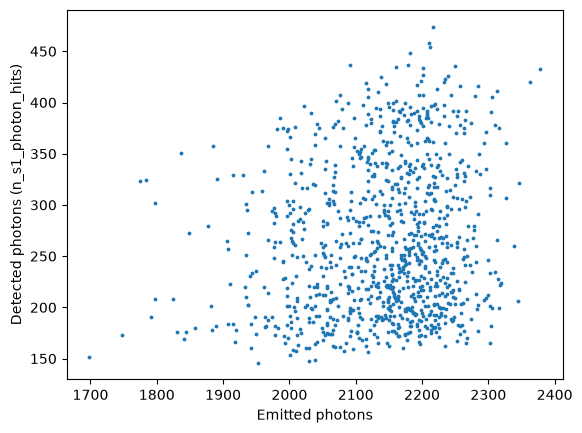

In [6]:
s1_photon_hits = st.get_array(run_id, ["microphysics_summary", "s1_photon_hits"])

plt.scatter(s1_photon_hits["photons"], s1_photon_hits["n_s1_photon_hits"], s=3)
plt.xlabel("Emitted photons")
plt.ylabel("Detected photons (n_s1_photon_hits)")
plt.show()

The fraction of detected photons depends on the position, as given by the map. Dividing by the emitted photons and multiplying with $1 + p_\mathrm{DPE}$ gives back the LCE:

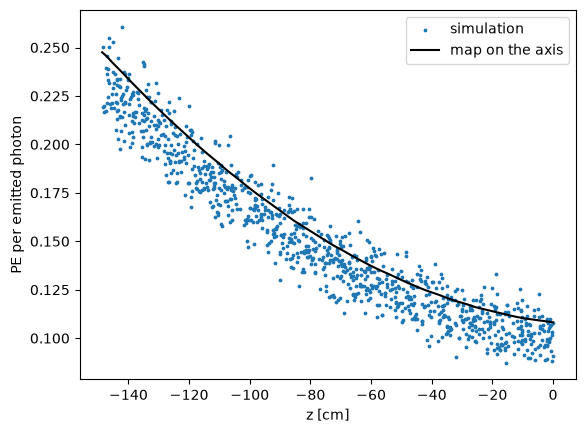

In [7]:
p_double_pe = strax.URLConfig.evaluate_dry("detector://p_double_pe_emission")
detected_fraction = s1_photon_hits["n_s1_photon_hits"] / s1_photon_hits["photons"] * (1 + p_double_pe)

plt.scatter(s1_photon_hits["z"], detected_fraction, s=3, label="simulation")
plt.plot(z_values, lce_total, color="black", label="map on the axis")
plt.xlabel("z [cm]")
plt.ylabel("PE per emitted photon")
plt.legend()
plt.show()

Changing an option changes the lineage, so strax simulates the data again (no new `run_id` needed). For example, halve the detection efficiency:

In [8]:
st_half = st.new_context()
st_half.set_config({"s1_detection_efficiency": 0.5})
half_hits = st_half.get_array(run_id, "s1_photon_hits")

print("Mean hits, efficiency 1.0:", s1_photon_hits["n_s1_photon_hits"].mean())
print("Mean hits, efficiency 0.5:", half_hits["n_s1_photon_hits"].mean())

Loading s1_photon_hits: |          | 0.00 % [00:00<?]

Mean hits, efficiency 1.0: 265.632
Mean hits, efficiency 0.5: 132.571


## 4. `S1PhotonPropagation`: channel, time and gain of every photon

This plugin turns the number of hits into individual photons. For every detected photon it does three things.

### 4.1 Channel

The channel is drawn from the hit pattern of the LCE map at the interaction position, $P(c) = \mathrm{LCE}_c / \sum_{c'} \mathrm{LCE}_{c'}$. Switched-off channels get $P = 0$. Because both plugins use the same map, the number of photons and their distribution over the PMTs are consistent.

The dummy map does not distinguish between channels within an array as we will see in a minute.


### 4.2 Arrival time

The arrival time is the sum of four parts:

1. **Interaction time** from `microphysics_summary`.
2. **Scintillation delay.** Photons come from excited xenon dimers in a singlet state (lifetime ≈ 3 ns) or a triplet state (≈ 24 ns), and some only after the recombination of an electron with an ion. NEST (`GetPhotonTimes`) draws these delays from the interaction type, the energy, the drift field and the exciton-to-photon ratio $N_\mathrm{ex}/N_\gamma$. Nuclear recoils produce more singlets and therefore faster S1s than electronic recoils. Delays above `maximum_recombination_time` are rejected and drawn again, so all photons stay inside a reasonable peak window.
3. **Optical propagation delay.** The time the photon needs to reach the PMT. Photons that hit a PMT directly arrive after a few ns, photons that are reflected several times on the walls after tens of ns. The timing map stores this distribution as a function of depth $z$, separately for the top and bottom array, as an *inverse cumulative distribution*: for a uniform random number $u \in [0, 1]$ the map returns the delay. Drawing $u$ uniformly therefore produces delays with the right distribution.

   ember's default timing map comes from a small optical toy Monte Carlo of the configured TPC (`ember.optical_toy_mc`, optical parameters from `detector.yaml`, see `map_generators/dummy_s1_timing_maps.ipynb`). If you have a full optical simulation of your detector (e.g. Geant4), replace the dummy map with its result (see section 6).
4. **PMT transit time.** The time the photoelectron needs from the photocathode to the first dynode, drawn from a Gaussian with mean `pmt_transit_time_mean` and FWHM `pmt_transit_time_spread`.

### 4.3 Gain

Each photon produces one PE, or two with probability $p_\mathrm{DPE}$ (column `dpe`). The charge of each PE fluctuates; it is drawn from the measured **SPE area distribution** of the channel, a spectrum with mean ≈ 1 PE. The column `photon_gain` is the PMT gain (electrons per PE) times the sampled SPE factor(s). The waveform simulation scales the SPE pulse shape with this number.

### Settings

| Option | Default | Meaning |
|---|---|---|
| `s1_pattern_map` | as in `S1PhotonHits` | channel probabilities |
| `s1_optical_propagation_spline` | `ember_map://s1_optical_propagation_dummy.json?method=linear` | optical delay; maps `top` and `bottom` in $(z, u)$ |
| `photon_area_distribution` | `ember_table://spe_distributions_dummy.csv` | SPE spectrum per channel (columns `charge, 0, 1, …`) |
| `gain_model_mc` + digitizer options | as in `S1PhotonHits` | PMT gains |
| `p_double_pe_emission` | 0.219 | DPE probability |
| `pmt_transit_time_mean` | 46 ns | mean PMT transit time |
| `pmt_transit_time_spread` | 9 ns | FWHM of the transit time ($\sigma = \mathrm{FWHM}/2.355$) |
| `maximum_recombination_time` | 1000 ns | scintillation delays above this value are drawn again |
| `nest_time_sampling_max_loops` | 10 | how often to redraw before giving up with an error (not tracked) |
| `n_top_pmts`, `n_tpc_pmts` | `detector://…` | the first `n_top_pmts` channels are the top array |

fuse has four more options that replace the NEST timing inputs of nuclear recoils by values tuned to XENONnT data (`override_s1_nr_scint_time` and `s1_nr_scint_time_*_override`). ember does not have them: the photon times always come from NEST.

In [9]:
st.show_config("propagated_s1_photons")

,option,default,current,applies_to,help
0,debug,False,<OMITTED>,"(propagated_s1_photons,)",Show debug informations
1,deterministic_seed,True,<OMITTED>,"(propagated_s1_photons,)","Set the random seed from lineage and run_id, o..."
2,user_defined_random_seed,None,<OMITTED>,"(propagated_s1_photons,)",Define the random seed manually. You need to s...
3,p_double_pe_emission,detector://p_double_pe_emission,<OMITTED>,"(propagated_s1_photons,)",Probability of double photo-electron emission
4,pmt_transit_time_spread,detector://pmt_transit_time_spread,<OMITTED>,"(propagated_s1_photons,)",Spread (FWHM) of the PMT transit times [ns]
...,...,...,...,...,...
56,w_value,detector://w_value_ev,<OMITTED>,"(clustered_interactions,)","Energy per quantum [eV], used to estimate the ..."
57,debug,False,<OMITTED>,"(electric_field_values,)",Show debug informations
58,deterministic_seed,True,<OMITTED>,"(electric_field_values,)","Set the random seed from lineage and run_id, o..."
59,user_defined_random_seed,None,<OMITTED>,"(electric_field_values,)",Define the random seed manually. You need to s...


In [10]:
s1_photons = st.get_array(run_id, "propagated_s1_photons")
print("Number of photons:", len(s1_photons))
print("Sum of n_s1_photon_hits:", s1_photon_hits["n_s1_photon_hits"].sum())
s1_photons[:5]

Loading propagated_s1_photons: |          | 0.00 % [00:00<?]

Number of photons: 265632
Sum of n_s1_photon_hits: 265632


array([(156, False, 3017135, 1, 1, 3091725653, 3091725653),
       ( 16, False, 5931414, 1, 1, 3091725654, 3091725654),
       (238, False, 5245702, 1, 1, 3091725654, 3091725654),
       ( 59, False, 1611424, 1, 1, 3091725657, 3091725657),
       (125,  True, 7645696, 1, 1, 3091725657, 3091725657)],
      dtype=[(('PMT channel of the photon', 'channel'), '<i2'), (('Photon creates a double photo-electron emission', 'dpe'), '?'), (('Sampled PMT gain for the photon', 'photon_gain'), '<i4'), (('ID of the cluster creating the photon', 'cluster_id'), '<i4'), (('Type of the photon. S1 (1), S2 (2) or PMT AP (0)', 'photon_type'), 'i1'), (('Start time since unix epoch [ns]', 'time'), '<i8'), (('Exclusive end time since unix epoch [ns]', 'endtime'), '<i8')])

### Which PMTs see the light?

Count the photons per channel. The dummy map gives every PMT of one array the same probability, so we see two flat levels:

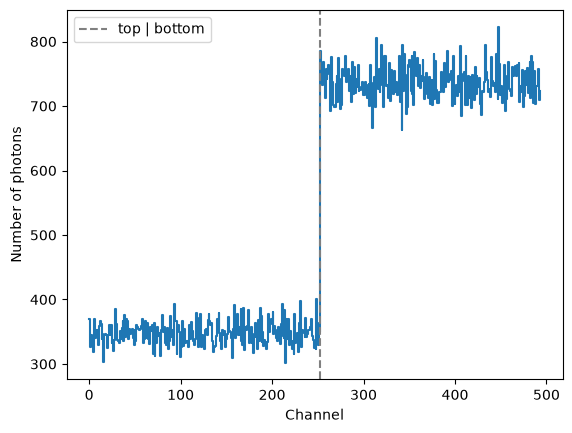

AFT of all photons: 0.3312025659559089


In [11]:
photons_per_channel = np.bincount(s1_photons["channel"], minlength=n_tpc_pmts)

plt.step(np.arange(n_tpc_pmts), photons_per_channel, where="mid")
plt.axvline(n_top_pmts - 0.5, color="gray", linestyle="--", label="top | bottom")
plt.xlabel("Channel")
plt.ylabel("Number of photons")
plt.legend()
plt.show()

is_top = s1_photons["channel"] < n_top_pmts
print("AFT of all photons:", is_top.mean())

### The S1 time profile

To see the pulse shape, subtract the time of the interaction that produced each photon. `cluster_id` links each photon to its interaction:

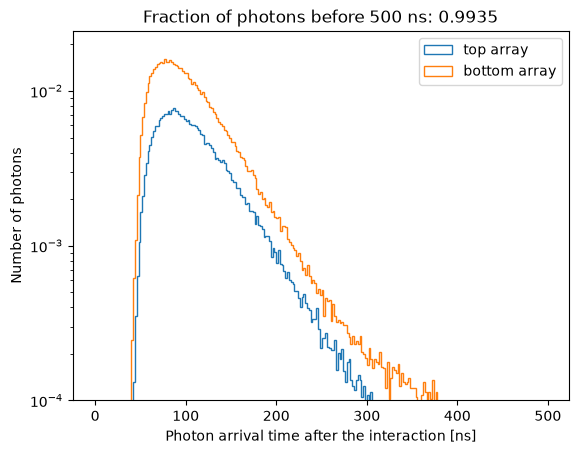

In [12]:
interaction_time = dict(zip(microphysics_summary["cluster_id"], microphysics_summary["time"]))
delay = s1_photons["time"] - np.array([interaction_time[cluster] for cluster in s1_photons["cluster_id"]])


weight = np.ones(len(delay))/len(delay)
bins = np.arange(0, 500, 2)
plt.hist(delay[is_top], bins=bins, histtype="step", label="top array", weights=weight[is_top])
plt.hist(delay[~is_top], bins=bins, histtype="step", label="bottom array", weights=weight[~is_top])
plt.yscale("log")
plt.xlabel("Photon arrival time after the interaction [ns]")
plt.ylabel("Number of photons")
plt.legend()
plt.ylim(10**-4, None)
fraction = np.sum(delay < 500)/len(delay)
plt.title(f'Fraction of photons before 500 ns: {fraction:.4f}')
plt.show()

The rise at about 46 ns is the PMT transit time. After the fast singlet component the distribution falls off with the triplet lifetime and the recombination tail. The optical delay adds a few ns to tens of ns. It differs between the two arrays, because the photons travel different distances to them. The cell below shows the timing map for an interaction at mid depth. The dummy map comes from ember's optical toy Monte Carlo (see `map_generators/dummy_s1_timing_maps.ipynb`); replace it with the result of a full optical simulation of your detector if you have one.

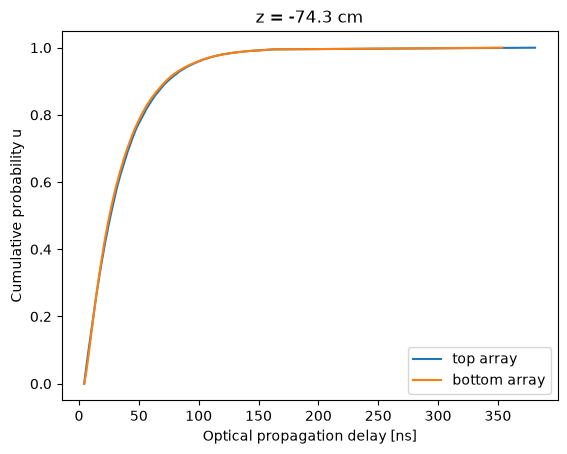

In [13]:
timing_map = strax.URLConfig.evaluate_dry(
    "ember_map://s1_optical_propagation_dummy.json?method=linear"
)

u_values = np.linspace(0, 1, 200)
z_mid = z_cathode / 2
positions_z_u = np.column_stack([np.full(200, z_mid), u_values])

plt.plot(timing_map(positions_z_u, map_name="top"), u_values, label="top array")
plt.plot(timing_map(positions_z_u, map_name="bottom"), u_values, label="bottom array")
plt.xlabel("Optical propagation delay [ns]")
plt.ylabel("Cumulative probability u")
plt.title(f"z = {z_mid:.1f} cm")
plt.legend()
plt.show()

### Gains and double photoelectron emission

Fraction of photons with DPE: 0.2199772617756897 (p_DPE = 0.219 )


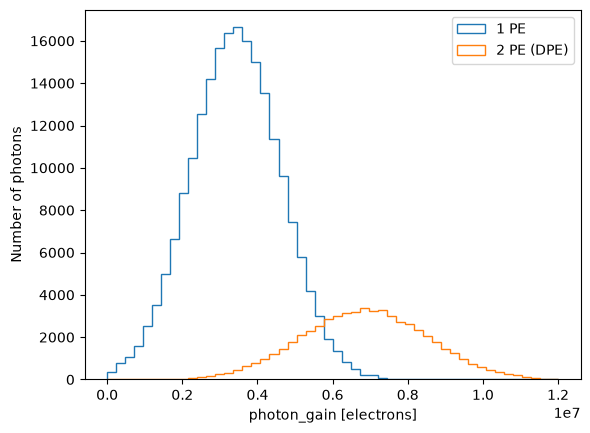

In [14]:
print("Fraction of photons with DPE:", s1_photons["dpe"].mean(), "(p_DPE =", p_double_pe, ")")

plt.hist(s1_photons["photon_gain"][~s1_photons["dpe"]], bins=50, range=(0, 1.2*10**7), histtype="step", label="1 PE")
plt.hist(s1_photons["photon_gain"][s1_photons["dpe"]], bins=50, range=(0, 1.2*10**7), histtype="step", label="2 PE (DPE)")
plt.xlabel("photon_gain [electrons]")
plt.ylabel("Number of photons")
plt.legend()
plt.show()

## 5. Nuclear recoils have a faster S1

Write 1000 nuclear recoils of 20 keV (NEST id 0) at the same positions as the betas and compare the time profiles. Both use the same positions, so the optical delays are the same and the difference comes from the scintillation. We use the photons of the bottom array in both cases.

Source finished!


Loading propagated_s1_photons: |          | 0.00 % [00:00<?]

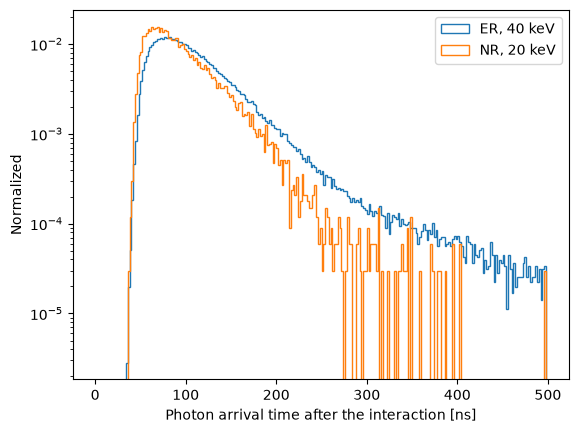

In [15]:
import pandas as pd

nr_instructions = pd.read_csv("beta_40keV.csv")
nr_instructions["ed"] = 20.0
nr_instructions["nestid"] = 0
nr_instructions.to_csv("nr_20keV.csv", index=False)

st_nr = st.new_context()
st_nr.set_config({"input_file": "nr_20keV.csv"})
nr_summary = st_nr.get_array("000004", "microphysics_summary")
nr_photons = st_nr.get_array("000004", "propagated_s1_photons")

nr_interaction_time = dict(zip(nr_summary["cluster_id"], nr_summary["time"]))
nr_delay = nr_photons["time"] - np.array(
    [nr_interaction_time[cluster] for cluster in nr_photons["cluster_id"]]
)
nr_is_bottom = nr_photons["channel"] >= n_top_pmts

plt.hist(delay[~is_top], bins=bins, histtype="step", density=True, label="ER, 40 keV")
plt.hist(nr_delay[nr_is_bottom], bins=bins, histtype="step", density=True, label="NR, 20 keV")
plt.yscale("log")
plt.xlabel("Photon arrival time after the interaction [ns]")
plt.ylabel("Normalized")
plt.legend()
plt.show()

## 6. Use your own maps

All maps are config options, so you can point them to your own files, for example the result of an optical simulation of your detector. Maps in `ember/dummy_maps` can be given by name, other files by absolute path:

```python
st.set_config({
    "s1_pattern_map": "ember_map:///path/to/my_s1_lce_map.pkl?method=linear",
    "s1_optical_propagation_spline": "ember_map:///path/to/my_s1_timing.json?method=linear",
    "photon_area_distribution": "ember_table:///path/to/my_spe_spectra.csv",
})
```

Requirements:

* the LCE map has one entry per channel along its last axis (`n_tpc_pmts` entries) and is in PE per emitted photon, including DPE (on average $g_1$);
* the timing map has the axes `z` and `u` and two maps called `top` and `bottom`, and is non-decreasing in `u`;
* the SPE table has a column `charge` and one column per channel, named `0, 1, …`.

See the notebooks in `map_generators/` for the file formats.

**Important:** strax hashes the URL, not the file content. If you overwrite a map file under the same name, strax reuses the old data. Use a new file name or delete the stored data.

Secondly, when using absolute paths you run into an issue if you want to access data on different systems! Since the url is hashed a change in an aboslute path will change the lineage of the data!

## Summary

* `S1PhotonHits` draws the number of detected photons from the LCE map: $N_\mathrm{hits} \sim \mathrm{Binomial}(N_\gamma, \varepsilon_\mathrm{LCE}\,\varepsilon_{S1}/(1 + p_\mathrm{DPE}))$.
* `S1PhotonPropagation` gives each photon a channel (LCE map), an arrival time (NEST scintillation + optical timing map + PMT transit time) and a gain (PMT gain × SPE spectrum, DPE).
* Three inputs are maps or tables: the LCE map, the optical timing map and the SPE spectra. ember ships dummy versions.
* The output `propagated_s1_photons` has one row per photon and is the input of the PMT and DAQ simulation.